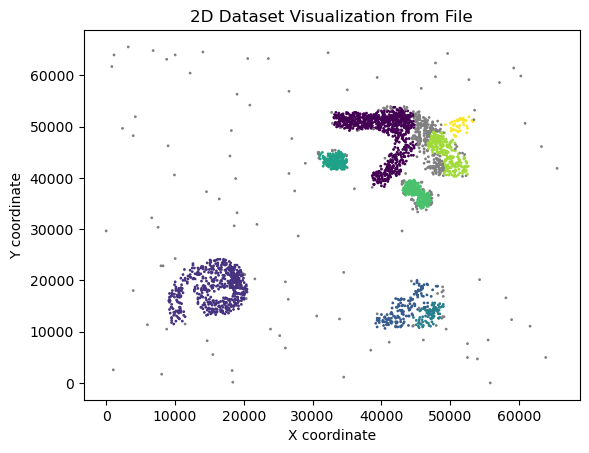

In [13]:
import csv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import minmax_scale

x_coords = []
y_coords = []
cluster_ids = []

# Open and read the dataset from 'data.csv'
with open('my-file-2d.txt', 'r') as file:
    reader = csv.reader(file, delimiter=',')
    for row in reader:
        x, y, c = map(float, row)
        x_coords.append(x)
        y_coords.append(y)
        cluster_ids.append(c)


# Sample data
df = pd.DataFrame({'a':x_coords, 'b':y_coords, 'c':cluster_ids})

# MinMax normalize all numeric columns
cols = df.select_dtypes(np.number).columns
df['a'] = minmax_scale(df['a'])*pow(2,16)
df['b'] = minmax_scale(df['b'])*pow(2,16)

df['a'] = df['a'].astype('int32')
df['b'] = df['b'].astype('int32')

x_coords = df['a']
y_coords = df['b']


colors = ['gray' if cluster_id == -1 else 'viridis' for cluster_id in cluster_ids]

# COLORS
unique_clusters = set(cluster_ids)
if -1 in unique_clusters:
    unique_clusters.remove(-1)
unique_colors = plt.cm.viridis(np.linspace(0, 1, len(unique_clusters)))
cluster_to_color = {cluster_id: color for cluster_id, color in zip(unique_clusters, unique_colors)}
cluster_to_color[-1] = 'gray'  # Override color for cluster -1 to gray
point_colors = [cluster_to_color[cluster_id] for cluster_id in cluster_ids]

# Plotting
plt.scatter(x_coords, y_coords, c=point_colors, s=1)
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.title('2D Dataset Visualization from File')
plt.show()

df.to_csv('data.txt', sep=',', index=False)


In [4]:
pow(2,32)


4294967296